# Bangladesh Rent Prediction: EDA
**Goal:** predict monthly apartment rent (BDT) from area, beds, baths, type and location.
**Data:** 7,557 listings from bproperty (Dhaka and Chattogram), all "For Rent".

## 1. Data inspection
- 7,557 rows, 11 columns, no missing values, but every column is stored as text.
- Price, area, beds and bath need parsing (e.g. "1.1 Lakh", "2,200 sqft", "1 Bed").
- `title`, `url` and `flooPlan` are links or text, so I drop them.

In [ ]:
import pandas as pd

df = pd.read_csv("../data/property_listing_data_in_Bangladesh.csv")
df.head()
df.shape
df.info()
df.describe()
df.isna().sum()
df.duplicated().sum()
df

In [ ]:
print(df.shape)
print(df.dtypes)
print((df.isna().mean() * 100).round(1))
print("duplicates:", df.duplicated().sum())
for c in df.select_dtypes("object").columns:
    print(c, df[c].nunique(), df[c].unique()[:5].tolist())
df.head(3)

## 2. Cleaning
- Parsed price, area, beds and bath into numbers.
- Removed duplicate listings by URL.
- Removed impossible rows (e.g. 36 beds, 31,500 sqft) and rows with an implausible rent per sqft.
- Grouped localities with fewer than 20 listings into "Other".
- Final dataset: 7,448 rows, 50 localities, saved to `data/clean.csv`.

In [ ]:
import re

print(df["purpose"].value_counts())
print(df["type"].value_counts())
print(df["beds"].value_counts().head(10))
print(df["bath"].value_counts().head(10))

def parse_price(s):
    m = re.match(r"([\d.]+)\s*(thousand|lakh|crore)?", str(s).replace(",", "").strip(), re.I)
    if not m: return None
    try: num = float(m.group(1))
    except ValueError: return None
    return num * {"thousand": 1e3, "lakh": 1e5, "crore": 1e7, None: 1}[m.group(2).lower() if m.group(2) else None]

df["price_num"] = df["price"].apply(parse_price)
df["area_sqft"] = pd.to_numeric(df["area"].str.replace(r"[^\d.]", "", regex=True), errors="coerce")
df["city"] = df["adress"].str.split(",").str[-1].str.strip()

print(df[["price_num", "area_sqft"]].isna().sum())
print(df.groupby("purpose")["price_num"].describe())
print(df["city"].value_counts().head(10))

In [ ]:
df = df.drop_duplicates(subset="url")

df["beds_n"] = pd.to_numeric(df["beds"].str.extract(r"(\d+)")[0])
df["bath_n"] = pd.to_numeric(df["bath"].str.extract(r"(\d+)")[0])
df["locality"] = df["adress"].str.split(",").str[-2].str.strip()

use = ["price_num", "area_sqft", "beds_n", "bath_n", "type", "city", "locality"]
d = df[use]

print(d.shape)
print(d.isna().sum())
print(d.describe(percentiles=[.01, .05, .5, .95, .99]).T)
print(d["locality"].nunique())
print(d["locality"].value_counts().head(10))

In [ ]:
d = d.copy()
d["locality"] = d["locality"].fillna("Unknown")

d = d[
    d["area_sqft"].between(300, 6000)
    & d["beds_n"].between(1, 8)
    & d["bath_n"].between(1, 8)
    & d["price_num"].between(5000, 500000)
]

d["rent_per_sqft"] = d["price_num"] / d["area_sqft"]
print(d["rent_per_sqft"].describe(percentiles=[.01, .99]))
d = d[d["rent_per_sqft"].between(d["rent_per_sqft"].quantile(.005), d["rent_per_sqft"].quantile(.995))]

counts = d["locality"].value_counts()
rare = counts[counts < 20].index
d["locality"] = d["locality"].replace(dict.fromkeys(rare, "Other"))

d = d.drop(columns="rent_per_sqft")
print(d.shape, d["locality"].nunique())

d.to_csv("../data/clean.csv", index=False)

## 3. Exploratory analysis

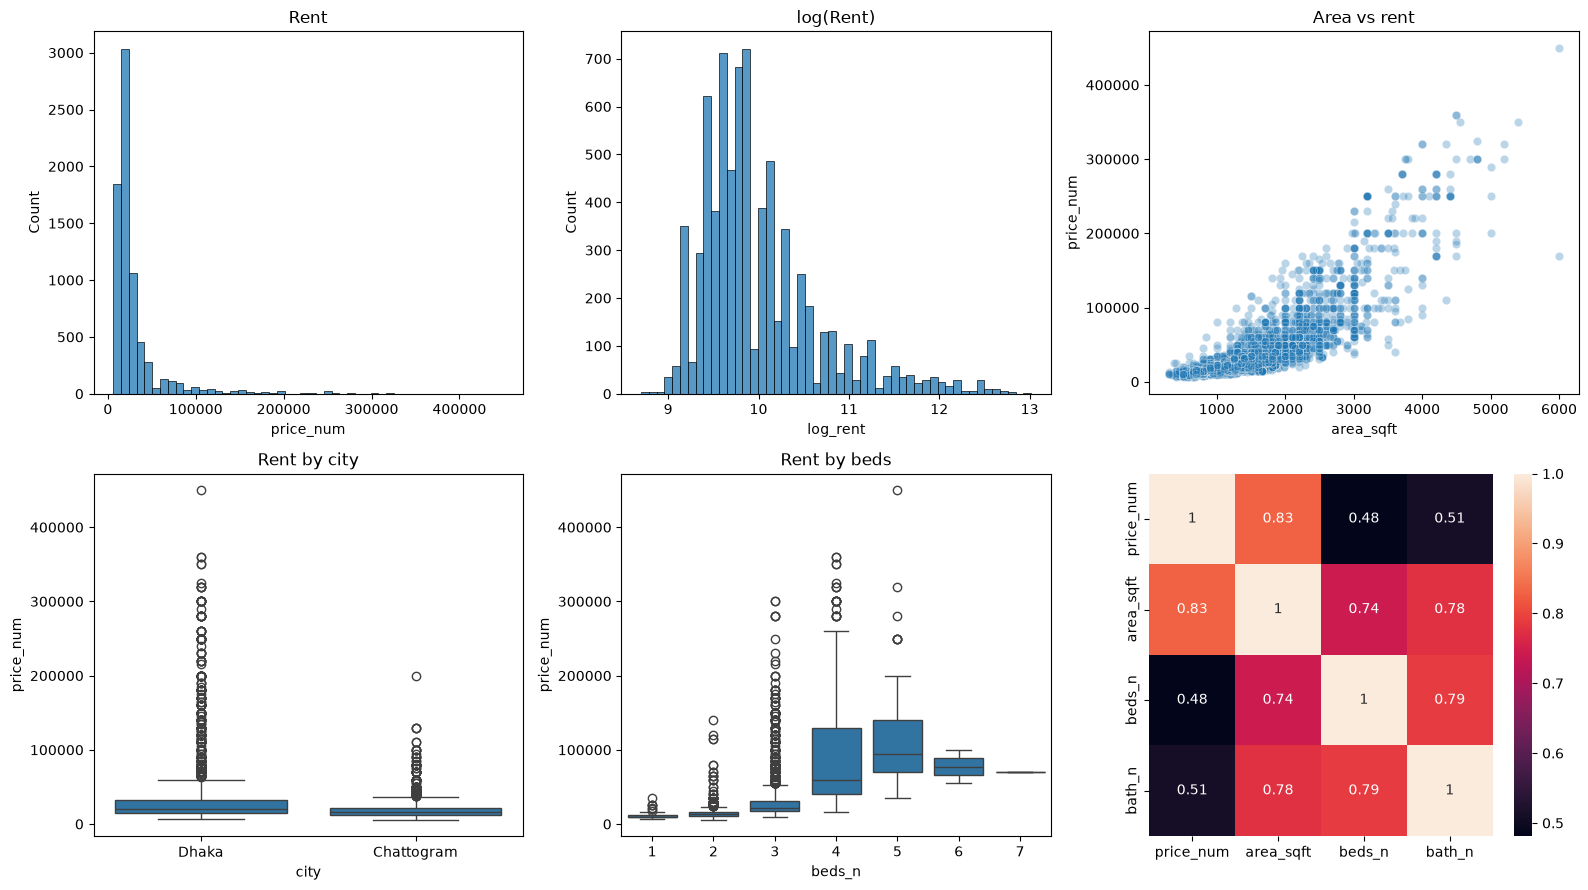

locality
Gulshan                     130000.0
Baridhara                   120000.0
Banani                       90000.0
Baridhara DOHS               70000.0
Dhanmondi                    45000.0
Eskaton                      35000.0
Motijheel                    35000.0
16 No. Chawk Bazaar Ward     32000.0
Bashundhara R-A              32000.0
15 No. Bagmoniram Ward       30000.0
Name: price_num, dtype: float64
locality
Bayazid                      13000.0
Khilkhet                     12500.0
10 No. North Kattali Ward    12000.0
Uttar Khan                   12000.0
Patenga                      11000.0
Name: price_num, dtype: float64


In [8]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

d = pd.read_csv("../data/clean.csv")
d["log_rent"] = np.log1p(d["price_num"])

fig, ax = plt.subplots(2, 3, figsize=(16, 9))

sns.histplot(d["price_num"], bins=50, ax=ax[0, 0]).set_title("Rent")
sns.histplot(d["log_rent"], bins=50, ax=ax[0, 1]).set_title("log(Rent)")
sns.scatterplot(data=d, x="area_sqft", y="price_num", alpha=.3, ax=ax[0, 2]).set_title("Area vs rent")
sns.boxplot(data=d, x="city", y="price_num", ax=ax[1, 0]).set_title("Rent by city")
sns.boxplot(data=d, x="beds_n", y="price_num", ax=ax[1, 1]).set_title("Rent by beds")
sns.heatmap(d[["price_num", "area_sqft", "beds_n", "bath_n"]].corr(), annot=True, ax=ax[1, 2])
plt.tight_layout()
plt.show()

top = d.groupby("locality")["price_num"].median().sort_values(ascending=False)
print(top.head(10)); print(top.tail(5))

**Rent distribution:** right-skewed (most listings under ~50k, max 450k); the log transform makes it much more symmetric, so I model log(rent).
**Area vs rent:** rent rises roughly linearly with area; the spread widens for flats above ~2,500 sqft.
**City:** Dhaka has higher median rent and many more high-end outliers than Chattogram.
**Beds:** rent rises with beds, but ranges overlap heavily, so area and location matter too.
**Correlation:** rent correlates most with area (r = 0.83), then baths (0.51) and beds (0.48). Area, beds and baths are strongly correlated with each other (0.74 to 0.79).
**Localities:** most expensive: Gulshan, Baridhara, Banani (median 90k to 130k); cheapest: Patenga, Uttar Khan, North Kattali (11k to 12k). Location is a major rent driver.